Synthetic phishing URL dataset created.
                                url  label
0            https://www.google.com      0
1      https://www.amazon.com/login      0
2         https://github.com/openai      0
3  https://www.microsoft.com/en-us/      0
4       https://www.paypal.com/home      0

Model Accuracy: 80.0 %

Confusion Matrix:
[[2 1]
 [0 2]]


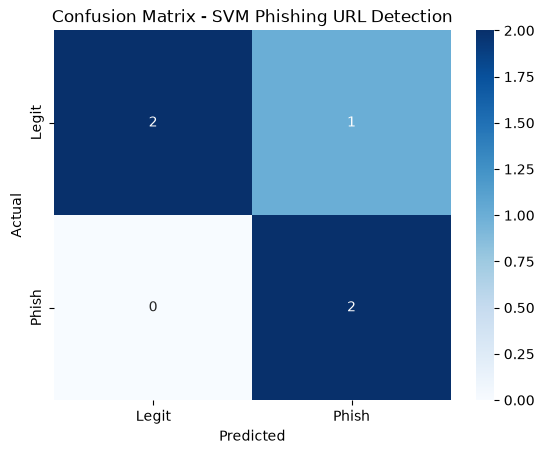


Classification Report:
              precision    recall  f1-score   support

       Legit       1.00      0.67      0.80         3
       Phish       0.67      1.00      0.80         2

    accuracy                           0.80         5
   macro avg       0.83      0.83      0.80         5
weighted avg       0.87      0.80      0.80         5


Model and vectorizer saved successfully.

URL Prediction Results:
https://secure-login-paypal-alert.info --> Phishing
https://www.amazon.in/gp/cart/view.html --> Legitimate
http://update-facebook-verification.com --> Phishing
https://accounts.google.com --> Phishing


In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

# ---------------- Step 1: Create Synthetic Dataset ----------------

data = {
    "url": [
        # Legitimate URLs
        "https://www.google.com",
        "https://www.amazon.com/login",
        "https://github.com/openai",
        "https://www.microsoft.com/en-us/",
        "https://www.paypal.com/home",
        "https://www.bankofamerica.com/security",
        "https://www.linkedin.com/in/johndoe",
        "https://www.apple.com/store",

        # Phishing URLs
        "http://paypal-login-security-alert.com",
        "http://verify-account-amazon.biz/login",
        "https://secure-facebook-login-update.ru",
        "http://bankofamerica-login-confirm.net",
        "https://google-account-reset-now.xyz",
        "http://microsoft-support-verification.top",
        "http://appleid-reset-alert.org",
        "https://login-update-github.io"
    ],

    "label": [
        0,0,0,0,0,0,0,0,
        1,1,1,1,1,1,1,1
    ]   # 0=Legit, 1=Phish
}

df = pd.DataFrame(data)

print("Synthetic phishing URL dataset created.")
print(df.head())

# ---------------- Step 2: Data Preprocessing ----------------

X = df["url"]
y = df["label"]

# Convert URL text into numerical vectors using TF-IDF
vectorizer = TfidfVectorizer(
    analyzer='char',
    ngram_range=(3,5)
)

X_vectorized = vectorizer.fit_transform(X)

# ---------------- Step 3: Split Data ----------------

X_train, X_test, y_train, y_test = train_test_split(
    X_vectorized,
    y,
    test_size=0.3,
    random_state=42
)

# ---------------- Step 4: Train SVM Model ----------------

model = SVC(kernel='linear')

model.fit(X_train, y_train)

# ---------------- Step 5: Evaluate Model ----------------

y_pred = model.predict(X_test)

acc = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:", acc * 100, "%")

print("\nConfusion Matrix:")

cm = confusion_matrix(y_test, y_pred)

print(cm)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Legit', 'Phish'],
    yticklabels=['Legit', 'Phish']
)

plt.title("Confusion Matrix - SVM Phishing URL Detection")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=['Legit', 'Phish']
    )
)

# ---------------- Step 6: Save Model & Vectorizer ----------------

joblib.dump(model, "svm_phishing_url_model.pkl")

joblib.dump(vectorizer, "svm_phishing_vectorizer.pkl")

print("\nModel and vectorizer saved successfully.")

# ---------------- Step 7: Test with New URLs ----------------

new_urls = [
    "https://secure-login-paypal-alert.info",
    "https://www.amazon.in/gp/cart/view.html",
    "http://update-facebook-verification.com",
    "https://accounts.google.com"
]

new_features = vectorizer.transform(new_urls)

predictions = model.predict(new_features)

print("\nURL Prediction Results:")

for url, pred in zip(new_urls, predictions):

    status = "Phishing" if pred == 1 else "Legitimate"

    print(f"{url} --> {status}")